# 05 — Mother More Educated Than Father

## Purpose

So far we have looked at mother's and father's education separately. In this notebook we look at the **education gap between parents**. Growing up in a household where the mother is more educated than the father may expose children to a less traditional division of roles at home, which could be linked to less traditional gender-role attitudes later in life.

We create a new variable, **`mother_more_educated`**, using the grouped parental education levels (Q277R and Q278R):

- **1** = the mother's education level is **higher** than the father's
- **0** = the mother's education level is **equal to or lower** than the father's
- **Missing** = either parent's education is missing

**Important note on the grouped levels:** because we compare *grouped* levels (1 = Lower, 2 = Middle, 3 = Higher), a mother only counts as more educated if she is in a **higher group** than the father. For example, if the mother has a bachelor's degree (ISCED 6) and the father has a short-cycle tertiary diploma (ISCED 5), both are in the "Higher" group, so the mother is **not** counted as more educated. Our variable therefore only captures fairly large education gaps and will miss smaller ones.

**Important note on the comparison group:** the "0" group combines two quite different kinds of families: those where both parents are at the **same** level, and those where the **father is more educated**. Comparing "mother more educated" with this mixed group is harder to interpret, so in Section 7.1 we also compare **three groups** (mother more educated, same level, father more educated) and save this as a second variable, **`parent_education_gap`**.

We then test whether `mother_more_educated` is associated with traditional gender-role attitudes, and save the new variables into the cleaned dataset.

### Hypotheses

**H0c:** There is no difference in traditional gender-role attitudes between respondents whose mother is more educated than their father and other respondents.

**H1c:** There is a difference in traditional gender-role attitudes between the two groups.

As in `03_correlations.ipynb`, the test is two-tailed because we are testing whether there is a difference, rather than predicting its direction beforehand.

## 1. Setup and Data Loading

We import the same packages as in class and load the cleaned dataset created in `04_reclean_full.ipynb`. From `scipy.stats` we use `pearsonr` (week 4) and `ttest_ind` for the independent-samples t-test, and in Section 7.1 we use `smf.ols` (Week 5) with a categorical predictor.

In [1]:
from pathlib import Path  # used to build file paths that work on any computer

import pandas as pd  # data management (DataFrames)
import numpy as np  # numerical tools, e.g. np.nan and np.where
from plotnine import *  # ggplot-style figures, as used in class
from scipy import stats  # statistical tests (t-test and correlation)
import statsmodels.formula.api as smf  # OLS with a categorical predictor (Section 7.1)
import warnings  # lets us silence routine warnings
warnings.filterwarnings('ignore')  # hide warnings so the output is easier to read

In [2]:
# Identify the root folder of the GitHub repository.
PROJECT_ROOT = Path.cwd()  # start from the folder the notebook is running in
if PROJECT_ROOT.name == "code":  # if we are inside the /code folder...
    PROJECT_ROOT = PROJECT_ROOT.parent  # ...move up one level to the repository root

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "WVS_Singapore_full_cleaned.csv"  # cleaned dataset from notebook 04
OUTPUT_FIGURES = PROJECT_ROOT / "output" / "figures"  # folder for saved figures
OUTPUT_TABLES = PROJECT_ROOT / "output" / "tables"  # folder for saved tables

df = pd.read_csv(DATA_PATH)  # load the cleaned dataset

print(f"Number of respondents: {df.shape[0]}")  # number of rows
print(f"Number of variables: {df.shape[1]}")  # number of columns

Number of respondents: 2012
Number of variables: 48


## 2. Comparing Mother's and Father's Education

Before creating the new variable, we cross-tabulate mother's and father's education levels. This shows how often the two parents are in the same group and how often they differ.

In [3]:
edu_labels = {1.0: "Lower", 2.0: "Middle", 3.0: "Higher"}  # labels for the grouped education levels
edu_order = ["Lower", "Middle", "Higher"]  # the order in which the levels should be shown

parents = pd.crosstab(  # count respondents for every combination of mother's and father's education
    df["Q277R"].map(edu_labels), df["Q278R"].map(edu_labels),  # use the labels instead of 1, 2, 3
    rownames=["Mother's education"], colnames=["Father's education"],  # name the rows and columns
).reindex(index=edu_order, columns=edu_order)  # put the levels in order

parents.to_csv(OUTPUT_TABLES / "mother_by_father_education_crosstab.csv")  # save the table
parents  # display the table

Father's education,Lower,Middle,Higher
Mother's education,,,
Lower,1021,182,42
Middle,67,240,86
Higher,8,33,129


In [4]:
both_valid = df[["Q277R", "Q278R"]].dropna()  # respondents who reported both parents' education
rho, p = stats.spearmanr(both_valid["Q277R"], both_valid["Q278R"])  # Spearman correlation between the two (both ordinal)
print(f"N = {len(both_valid)}")  # number of respondents used
print(f"Spearman's rho between mother's and father's education = {rho:.3f}, p-value = {p:.4g}")  # print the result

N = 1808
Spearman's rho between mother's and father's education = 0.687, p-value = 1.702e-252


### Interpretation

The cross-table shows that most respondents' parents were at the **same education level**. The diagonal cells (1,021 + 240 + 129 = **1,390** respondents) are the largest in every row. The most common combination by far is two parents with lower education (**1,021** respondents).

Spearman's rho between mother's and father's education is **ρ = .687** (p < .001, N = 1,808), a **strong positive correlation**. People tended to marry partners with a similar level of education. This matters for the later notebooks: because the two parents' education levels overlap so much, it will be hard to separate the effect of the mother's education from that of the father's when both are in the same regression model. We will check this with variance inflation factors (VIFs) in `08_multivariate_models.ipynb`.

Cells **below** the diagonal are households where the mother is in a higher group than the father (67 + 8 + 33 = **108**), and cells **above** the diagonal are households where the father is in a higher group (182 + 42 + 86 = **310**). Fathers were about three times as likely as mothers to be the more educated parent, which reflects the gender gap in education in the parents' generation.

## 3. Creating `mother_more_educated`

We now create the new variable. We use `np.where`, as in class, to set it to 1 when the mother's level is higher than the father's and 0 otherwise. We then set it to missing for anyone with missing education for either parent. Without this step, `np.where` would wrongly code these respondents as 0, because comparing a missing value gives `False`.

In [5]:
df["mother_more_educated"] = np.where(df["Q277R"] > df["Q278R"], 1, 0)  # 1 if mother's level is higher, otherwise 0
either_missing = df["Q277R"].isna() | df["Q278R"].isna()  # True if mother's OR father's education is missing
df.loc[either_missing, "mother_more_educated"] = np.nan  # set the new variable to missing for these respondents

counts = df["mother_more_educated"].map({1.0: "1 Mother more educated", 0.0: "0 Equal or father more educated"})  # labels
counts = counts.fillna("Missing (either parent)").value_counts().reindex(  # count each group, including missing...
    ["1 Mother more educated", "0 Equal or father more educated", "Missing (either parent)"])  # ...in a fixed order
group_table = pd.DataFrame({  # build a frequency table
    "Frequency": counts,  # number of respondents
    "Percentage of full sample (%)": (counts / len(df) * 100).round(1),  # percentage of all 2,012 respondents
    "Percentage of valid cases (%)": (counts / df["mother_more_educated"].notna().sum() * 100).round(1),  # % of non-missing
})
group_table.loc["Missing (either parent)", "Percentage of valid cases (%)"] = np.nan  # this percentage does not apply to missing

group_table.to_csv(OUTPUT_TABLES / "mother_more_educated_distribution.csv")  # save the table
group_table  # display the table

,Frequency,Percentage of full sample (%),Percentage of valid cases (%)
mother_more_educated,,,
1 Mother more educated,108,5.4,6.0
0 Equal or father more educated,1700,84.5,94.0
Missing (either parent),204,10.1,NaN


In [6]:
# Break the "0" group down further, to see how many parents are equal and how many fathers are more educated.
gap = np.select(  # assign one of three labels depending on which parent has the higher level
    [df["Q277R"] > df["Q278R"], df["Q277R"] == df["Q278R"], df["Q277R"] < df["Q278R"]],  # the three conditions
    ["Mother more educated", "Same level", "Father more educated"], default="Missing")  # the matching labels

pd.Series(gap).value_counts()  # count respondents in each of the three groups

Same level              1390
Father more educated     310
Missing                  204
Mother more educated     108
Name: count, dtype: int64

### Interpretation

Out of the **1,808** respondents who reported both parents' education:

- **108 (6.0%)** have a mother who is in a higher education group than their father (`mother_more_educated` = 1);
- **1,700 (94.0%)** have parents at the same level (1,390) or a father who is more educated (310) (`mother_more_educated` = 0).

**204 respondents (10.1% of the full sample)** are missing because the education of at least one parent was not reported.

Note that the 0 group mixes **same-level** families (1,390) with **father-more-educated** families (310). We return to this in Section 7.1.

The "mother more educated" group is **very small**. This has two consequences:

1. Any estimate for this group is based on only about 100 people, so it will be less precise, and the test has less power to detect small differences.
2. As explained above, because we compare grouped levels, smaller education gaps within the same group are not counted, which partly explains why the group is so small.

## 4. Traditional Gender-Role Attitudes by Group

We first describe the traditional gender-role attitude scores in each group (number of respondents, mean, standard deviation and median), and show the distributions with a boxplot, as in `03_correlations.ipynb`.

In [7]:
test_data = df.dropna(subset=["mother_more_educated", "traditional_gender_attitudes"]).copy()  # complete cases for this test
test_data["group"] = test_data["mother_more_educated"].map({1.0: "Mother more educated", 0.0: "Equal or father more educated"})  # labels

group_desc = (test_data.groupby("group")["traditional_gender_attitudes"]  # group the scores by the new variable
              .agg(["count", "mean", "std", "median"])  # calculate the descriptive statistics
              .reindex(["Equal or father more educated", "Mother more educated"]))  # fixed order of the rows

group_desc.to_csv(OUTPUT_TABLES / "mother_more_educated_gender_attitudes_descriptives.csv")  # save the table
group_desc.round(3)  # display the table

,count,mean,std,median
group,,,,
Equal or father more educated,1669,2.119,0.556,2.0
Mother more educated,104,1.906,0.534,2.0


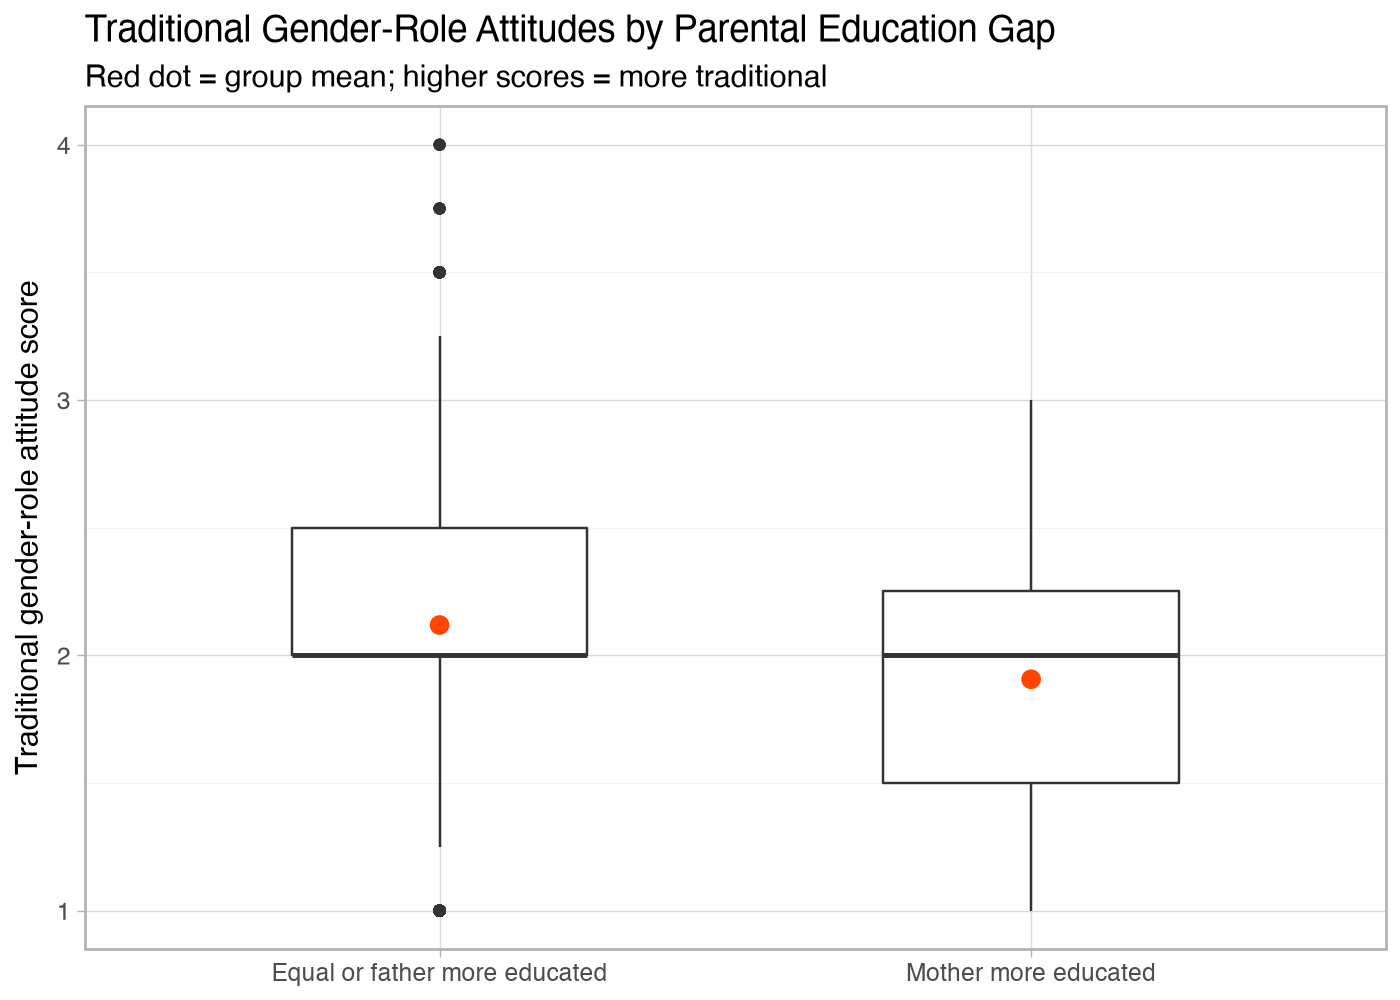

In [8]:
p = (
    ggplot(test_data, aes(x="group", y="traditional_gender_attitudes"))  # x = group, y = gender-role score
    + geom_boxplot(width=0.5)  # draw a boxplot for each group
    + stat_summary(fun_y=np.mean, geom="point", color="orangered", size=3)  # add the group mean as a red dot
    + theme_light()  # clean background, as in class
    + labs(x="", y="Traditional gender-role attitude score",  # axis labels
           title="Traditional Gender-Role Attitudes by Parental Education Gap",  # title
           subtitle="Red dot = group mean; higher scores = more traditional")  # subtitle
    + theme(figure_size=(7, 5))  # figure size
)
p.save(OUTPUT_FIGURES / "mother_more_educated_gender_attitudes_boxplot.png", dpi=300, verbose=False)  # save the figure
p  # display the figure

### Interpretation

Respondents whose mother is more educated than their father have a **lower** mean traditional gender-role score (**M = 1.906**, SD = 0.534, n = 104) than other respondents (**M = 2.119**, SD = 0.556, n = 1,669). Since higher scores mean more traditional attitudes, this suggests that respondents with a more educated mother hold **less traditional** gender-role attitudes.

The median is **2.0** in both groups, but the boxplot shows that the middle half of the scores sits lower for respondents with a more educated mother (roughly **1.5 to 2.25**, compared with **2.0 to 2.5** for the other group). There is still a large overlap between the two distributions. As in `03_correlations.ipynb`, the difference is mainly a modest downward shift of the whole distribution rather than a clear separation between the groups. A formal test is needed to see whether this difference is larger than we would expect by chance.

## 5. Independent-Samples t-test

To formally test whether the two groups differ, we use an **independent-samples t-test**, which compares the mean score of two separate groups. We did not run a t-test in class, so we briefly explain it here:

- The t-test asks whether the difference between the two group means is larger than we would expect by chance if the true population means were equal.
- We use **Welch's version** (`equal_var=False`), which does not assume that the two groups have the same variance. This is the safer choice here because the groups are very different in size.

**H₀: μ(mother more educated) = μ(equal or father more educated)**

**H₁: μ(mother more educated) ≠ μ(equal or father more educated)**

We also calculate **Cohen's d**, which expresses the difference between the means in standard-deviation units. As a rough guide, d ≈ 0.2 is a small effect, 0.5 medium and 0.8 large.

In [9]:
group1 = test_data.loc[test_data["mother_more_educated"] == 1, "traditional_gender_attitudes"]  # scores: mother more educated
group0 = test_data.loc[test_data["mother_more_educated"] == 0, "traditional_gender_attitudes"]  # scores: equal or father more

t_stat, t_p = stats.ttest_ind(group1, group0, equal_var=False)  # Welch's independent-samples t-test

pooled_sd = np.sqrt(((len(group1) - 1) * group1.var() + (len(group0) - 1) * group0.var())  # pooled standard deviation
                    / (len(group1) + len(group0) - 2))
cohens_d = (group1.mean() - group0.mean()) / pooled_sd  # Cohen's d: mean difference in SD units

print(f"N (mother more educated) = {len(group1)}, N (equal or father more educated) = {len(group0)}")  # group sizes
print(f"Mean difference (1 - 0) = {group1.mean() - group0.mean():.3f}")  # difference between the group means
print(f"Welch's t = {t_stat:.3f}, p-value = {t_p:.4g}")  # test statistic and p-value
print(f"Cohen's d = {cohens_d:.3f}")  # effect size

N (mother more educated) = 104, N (equal or father more educated) = 1669
Mean difference (1 - 0) = -0.212
Welch's t = -3.924, p-value = 0.0001474
Cohen's d = -0.383


### Interpretation

Welch's t-test shows a **statistically significant difference** between the two groups, **t = −3.924, p < .001** (n = 104 vs. 1,669). Respondents whose mother is more educated than their father scored on average **0.212 points lower** on the 1–4 traditional gender-role scale.

If there were truly no difference between the two groups in the population, the probability of observing a difference at least this large would be about **0.015%** (p = .00015). This is very unlikely under the null hypothesis, so we **reject H0c** and conclude that the two groups differ in their traditional gender-role attitudes. This is a difference between groups of respondents. It does **not** show that having a more educated mother *causes* less traditional attitudes. Section 7 shows that much of the difference reflects the mother's overall education level.

Cohen's d is **−0.383**, which is a **small-to-medium effect**. The groups differ by a little over one-third of a standard deviation. The negative sign means the "mother more educated" group is less traditional.

## 6. Point-Biserial Correlation

We also calculate the correlation between `mother_more_educated` and the gender-role score. When one variable is binary (0/1) and the other is continuous, the Pearson correlation from class (`stats.pearsonr`) is called the **point-biserial correlation**. It tells us the direction and strength of the association on the same scale as the Spearman correlations in `03_correlations.ipynb`.

**H₀: r = 0**  **H₁: r ≠ 0**

In [10]:
r, r_p = stats.pearsonr(test_data["mother_more_educated"], test_data["traditional_gender_attitudes"])  # point-biserial r

print(f"N = {len(test_data)}")  # number of respondents used
print(f"Point-biserial r = {r:.3f}, p-value = {r_p:.4g}")  # correlation and p-value

results = pd.DataFrame({  # collect the results into one table
    "Test": ["Welch's t-test", "Point-biserial correlation"],  # test names
    "N": [len(test_data), len(test_data)],  # sample size
    "Statistic": [t_stat, r],  # t value and r value
    "p-value": [t_p, r_p],  # p-values
    "Effect size": [f"Cohen's d = {cohens_d:.3f}", f"r = {r:.3f}"],  # effect sizes
})
results.to_csv(OUTPUT_TABLES / "mother_more_educated_tests.csv", index=False)  # save the table

N = 1773
Point-biserial r = -0.090, p-value = 0.000158


### Interpretation

The point-biserial correlation is **r = −.090, p < .001** (N = 1,773). This is a **statistically significant but very weak negative association**: having a mother who is more educated than one's father goes with slightly less traditional gender-role attitudes.

The correlation looks much smaller than Cohen's d (−0.383), even though both are based on the same data. This is because only 6% of respondents are in the "mother more educated" group. A correlation reflects how much of the variation in attitudes across the *whole sample* lines up with the variable, and a variable that applies to very few people cannot line up with much of it, even if the difference between the groups is meaningful. Cohen's d instead describes how far apart the two group means are.

Compared with `03_correlations.ipynb`, this association is weaker than the links with mother's education (ρ = −.171) and father's education (ρ = −.160) on their own.

## 7. Is the Difference Just About Mothers Being More Educated?

Respondents whose mother is more educated than their father must, by definition, have a mother with at least middle education. Since we already know from `03_correlations.ipynb` that more educated mothers are linked to less traditional attitudes, any difference we find could simply reflect the *mother's* education level rather than the *gap* between the parents.

As a first check, we compare respondents whose mothers are at the **same education level**, but who differ in whether the father is less educated. We cannot do this for the "Lower" group, because a mother with lower education can never be more educated than the father. This check is descriptive only. The multivariate models in `08_multivariate_models.ipynb` will test this properly by controlling for both parents' education.

In [11]:
within_mother = (test_data[test_data["Q277R"] >= 2]  # only mothers with middle or higher education
                 .assign(mother_level=lambda x: x["Q277R"].map(edu_labels))  # add a label for mother's level
                 .groupby(["mother_level", "group"])["traditional_gender_attitudes"]  # group by mother's level and gap group
                 .agg(["count", "mean", "std"]))  # descriptive statistics
within_mother.round(3)  # display the table

count   mean    std
mother_level group                                             
Higher       Equal or father more educated    127  1.846  0.662
             Mother more educated              41  1.768  0.520
Middle       Equal or father more educated    320  2.059  0.589
             Mother more educated              63  1.996  0.528

### Interpretation

When we only compare respondents whose mothers are at the **same** education level, the differences become much smaller:

- **Mothers with higher education:** respondents whose father was less educated scored **1.768** (n = 41), compared with **1.846** (n = 127) when the father was equally educated. This is a difference of only about 0.08 points.
- **Mothers with middle education:** **1.996** (n = 63) vs. **2.059** (n = 320), a difference of about 0.06 points.

In both cases, the "mother more educated" group is still slightly less traditional, but the gap is roughly **one-third the size** of the overall difference of 0.212. This suggests that much of the overall difference comes from the fact that these mothers are more educated in general, and only a small part may be linked to the mother being more educated *than the father*. These subgroups are small, so these numbers are only a rough guide. The regression models in `08_multivariate_models.ipynb` will test whether `mother_more_educated` still matters once both parents' education levels are controlled for.

### 7.1 Separating "Same Level" From "Father More Educated"

The "0" group in `mother_more_educated` combines families where both parents are at the **same** level with families where the **father is more educated**. These are substantively different households, so we now compare **three groups** directly:

- **Mother more educated** (Q277R > Q278R)
- **Same level** (Q277R = Q278R), used as the reference group
- **Father more educated** (Q277R < Q278R)

We describe the three groups, test the overall difference with an OLS model using `C()` (equivalent to a one-way ANOVA), and compare the pairs of groups with Welch's t-test and Cohen's d, as in Section 5. Finally, we add both parents' education levels to the model, to see whether the gap groups differ once the parents' own levels are taken into account.

In [12]:
gap_order = ["Mother more educated", "Same level", "Father more educated"]  # the three gap groups
df["parent_education_gap"] = pd.Series(gap, index=df.index).replace("Missing", np.nan)  # three-group variable (missing kept)
gap_data = df.dropna(subset=["parent_education_gap", "traditional_gender_attitudes"])  # complete cases

gap_desc = gap_data.groupby("parent_education_gap")["traditional_gender_attitudes"].agg(["count", "mean", "std"]).reindex(gap_order)
gap_desc.to_csv(OUTPUT_TABLES / "parent_education_gap_descriptives.csv")  # save the table
gap_desc.round(3)  # display the table

,count,mean,std
parent_education_gap,,,
Mother more educated,104,1.906,0.534
Same level,1365,2.140,0.554
Father more educated,304,2.021,0.559


In [13]:
gap_model = smf.ols("traditional_gender_attitudes ~ C(parent_education_gap, Treatment('Same level'))", data=gap_data).fit()  # three groups
print(f"Overall F = {gap_model.fvalue:.3f}, p-value = {gap_model.f_pvalue:.4g}")  # do the three groups differ?
print(gap_model.summary().tables[1])  # each group compared with 'Same level'


def compare(a, b):
    # Welch's t-test and Cohen's d for two of the gap groups.
    x = gap_data.loc[gap_data["parent_education_gap"] == a, "traditional_gender_attitudes"]  # scores in group a
    y = gap_data.loc[gap_data["parent_education_gap"] == b, "traditional_gender_attitudes"]  # scores in group b
    t, p = stats.ttest_ind(x, y, equal_var=False)  # Welch's t-test
    sd = np.sqrt(((len(x) - 1) * x.var() + (len(y) - 1) * y.var()) / (len(x) + len(y) - 2))  # pooled SD
    return {"Comparison": f"{a} vs {b}", "Mean difference": x.mean() - y.mean(), "Welch's t": t, "p-value": p,
            "Cohen's d": (x.mean() - y.mean()) / sd}


pairs = pd.DataFrame([compare("Mother more educated", "Same level"), compare("Father more educated", "Same level"),
                      compare("Mother more educated", "Father more educated")])  # all three pairs
pairs.to_csv(OUTPUT_TABLES / "parent_education_gap_comparisons.csv", index=False)  # save the table
pairs.round(4)  # display the table

Overall F = 12.950, p-value = 2.609e-06
                                                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                                    2.1403      0.015    142.896      0.000       2.111       2.170
C(parent_education_gap, Treatment('Same level'))[T.Father more educated]    -0.1189      0.035     -3.388      0.001      -0.188      -0.050
C(parent_education_gap, Treatment('Same level'))[T.Mother more educated]    -0.2340      0.056     -4.158      0.000      -0.344      -0.124


,Comparison,Mean difference,Welch's t,p-value,Cohen's d
0,Mother more educated vs Same level,-0.2340,-4.2954,0.0000,-0.4239
1,Father more educated vs Same level,-0.1189,-3.3594,0.0008,-0.2144
2,Mother more educated vs Father more educated,-0.1151,-1.8744,0.0624,-0.2082


In [14]:
gap_levels = smf.ols("traditional_gender_attitudes ~ C(parent_education_gap, Treatment('Same level')) + Q277R + Q278R",
                     data=gap_data).fit()  # gap groups plus both parents' education levels
print(gap_levels.summary().tables[1])  # coefficient table

                                                                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                                    2.3446      0.033     71.724      0.000       2.280       2.409
C(parent_education_gap, Treatment('Same level'))[T.Father more educated]     0.0163      0.102      0.160      0.873      -0.183       0.216
C(parent_education_gap, Treatment('Same level'))[T.Mother more educated]    -0.2189      0.107     -2.043      0.041      -0.429      -0.009
Q277R                                                                       -0.0199      0.085     -0.233      0.816      -0.187       0.147
Q278R                                                                       -0.1305      0.085     -1.543      0.123      -0.296       0.035


### Interpretation

**The three groups.** The **same-level** group is the **most traditional** (M = 2.140, n = 1,365), the **father-more-educated** group is in between (M = 2.021, n = 304) and the **mother-more-educated** group is the least traditional (M = 1.906, n = 104). The three groups differ significantly overall (F-test p < .001).

**Pairwise comparisons:**
- **Mother more educated vs. same level:** −0.234 points (Welch's t = −4.30, p < .001, d = −0.42).
- **Father more educated vs. same level:** −0.119 points (t = −3.36, p < .001, d = −0.21). So the father-more-educated families, which were hidden in the original "0" group, are *also* less traditional than same-level families.
- **Mother more educated vs. father more educated:** −0.115 points (t = −1.87, **p = .062**, d = −0.21). This difference is **not statistically significant** at α = .05.

Why is the same-level group the most traditional? Most same-level families are families where **both** parents had lower education (1,021 of 1,390), so this group mostly reflects low overall parental education. Any family with an education gap must have at least one parent above the lowest level.

**With both parents' education levels in the model**, the father-more-educated group no longer differs from the same-level group (b = +0.016, p = .873), while the mother-more-educated group remains somewhat less traditional (b = −0.219, p = .041). As discussed in `08_multivariate_models.ipynb`, the gap groups are fully determined by the two parents' levels, so this coefficient shows a departure from the numeric parental education pattern rather than the effect of changing the gap with both levels held fixed.

**What this means:** the original two-group comparison mixed two different families in its reference group. The three-group comparison shows that much of the "mother more educated" difference reflects higher parental education in general (which both gap groups have), and that the mother-more-educated and father-more-educated families do not differ significantly from each other. Any additional association specific to mothers being the more educated parent is small and uncertain.

## 8. Saving the Variable to the Cleaned Dataset

Finally, we save `mother_more_educated` and `parent_education_gap` into the cleaned dataset (`WVS_Singapore_full_cleaned.csv`), so the later notebooks can use it. The file is overwritten with the same data plus the new column. Re-running this notebook simply recreates the same column.

In [15]:
df.to_csv(DATA_PATH, index=False)  # save the dataset, now including mother_more_educated

check = pd.read_csv(DATA_PATH)  # reload the file to check that the variable was saved
print(f"mother_more_educated saved: {'mother_more_educated' in check.columns}")  # confirm the column exists
print(f"parent_education_gap saved: {'parent_education_gap' in check.columns}")  # confirm the three-group variable exists
print(check["mother_more_educated"].value_counts(dropna=False).sort_index())  # confirm the counts match the table above

mother_more_educated saved: True
parent_education_gap saved: True
mother_more_educated
0.0    1700
1.0     108
NaN     204
Name: count, dtype: int64


## Summary

- We created **`mother_more_educated`** (1 = mother in a higher education group than the father, 0 = same or lower, missing if either parent's education is missing). Only **108 respondents (6.0% of valid cases)** have a more educated mother, compared with 1,700 who do not. 204 are missing.
- Respondents whose mother is more educated than their father hold **less traditional** gender-role attitudes (M = 1.906 vs. 2.119). The difference is statistically significant (**Welch's t = −3.924, p < .001**) and small-to-medium in size (**Cohen's d = −0.383**). The point-biserial correlation is weak (**r = −.090, p < .001**) because the group is so small.
- When we compare respondents whose mothers have the **same** education level, the difference shrinks to about 0.06–0.08 points. This suggests that the overall difference mostly reflects the mother's own education rather than the gap between the parents.
- The "0" reference group combined same-level and father-more-educated families. Comparing **three groups** shows that same-level families are the most traditional (M = 2.140), father-more-educated families are in between (M = 2.021) and mother-more-educated families are the least traditional (M = 1.906). However, the mother-more-educated and father-more-educated groups do **not** differ significantly from each other (p = .062).
- Both variables (`mother_more_educated` and `parent_education_gap`) have been saved to `data/processed/WVS_Singapore_full_cleaned.csv`.

**Limitations:** this is a cross-sectional association, so we cannot say that having a more educated mother *causes* less traditional attitudes. Parental education is reported by the respondents. Because we compare grouped levels, smaller education gaps are not captured (e.g. ISCED 6 vs. ISCED 5 both count as "Higher"). The binary `mother_more_educated` variable also combines two different reference groups. Finally, the "mother more educated" group is small, so estimates for it are less precise.